In [ ]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Ready, seed =", SEED)

Ready, seed = 42


In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("mloey1/ahcd1")
print("Path:", path)

for f in glob.glob(path + "/**/*", recursive=True):
    if os.path.isfile(f):
        print(f, "|", round(os.path.getsize(f)/1e6, 1), "MB")

100%|██████████| 24.0M/24.0M [00:00<00:00, 209MB/s]

Extracting files...


Streaming output truncated to the last 5000 lines.
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_5211_label_8.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_9109_label_19.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_12818_label_7.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_9900_label_6.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_2127_label_14.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_374_label_19.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_1147_label_4.png | 0.0 MB
/root/.cache/kagglehub/datasets/mloey1/ahcd1/versions/2/Train Images 13440x32x32/train/id_6115_label_9.png | 0.0 MB
/root/.cache/kaggl

In [ ]:
csvs = sorted(glob.glob(path + "/**/*.csv", recursive=True))
data = {}
for f in csvs:
    df = pd.read_csv(f, header=None)
    data[os.path.basename(f)] = df
    print(os.path.basename(f), "->", df.shape)

csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)
csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)
csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)


In [ ]:
def find_csv(keyword):
    matches = [f for f in csvs if keyword in os.path.basename(f)]
    return matches[0]

X_train = pd.read_csv(find_csv("csvTrainImages"), header=None).values.astype("float32")
y_train = pd.read_csv(find_csv("csvTrainLabel"), header=None).values.ravel()
X_test  = pd.read_csv(find_csv("csvTestImages"), header=None).values.astype("float32")
y_test  = pd.read_csv(find_csv("csvTestLabel"), header=None).values.ravel()

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Labels range:", y_train.min(), "to", y_train.max())
print("Number of classes:", len(np.unique(y_train)))

X_train: (13440, 1024) | y_train: (13440,)
X_test: (3360, 1024) | y_test: (3360,)
Pixel range: 0.0 to 255.0
Labels range: 1 to 28
Number of classes: 28


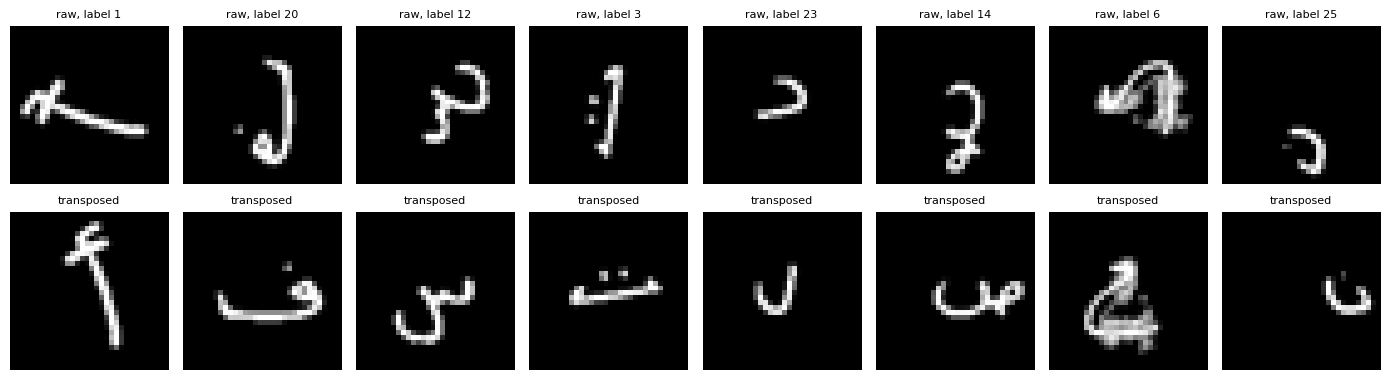

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    img = X_train[i * 1500].reshape(32, 32)
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title(f"raw, label {y_train[i * 1500]}", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(img.T, cmap="gray")
    axes[1, i].set_title("transposed", fontsize=8)
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

1     480
2     480
3     480
4     480
5     480
6     480
7     480
8     480
9     480
10    480
11    480
12    480
13    480
14    480
15    480
16    480
17    480
18    480
19    480
20    480
21    480
22    480
23    480
24    480
25    480
26    480
27    480
28    480


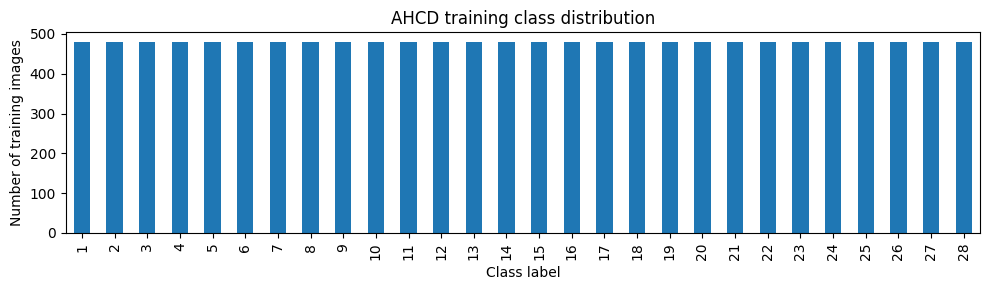

In [ ]:
train_counts = pd.Series(y_train).value_counts().sort_index()
print(train_counts.to_string())

plt.figure(figsize=(10, 3))
train_counts.plot(kind="bar")
plt.xlabel("Class label")
plt.ylabel("Number of training images")
plt.title("AHCD training class distribution")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

def preprocess(X):
    X = X.reshape(-1, 32, 32).transpose(0, 2, 1)
    X = X / 255.0
    return X[..., np.newaxis].astype("float32")

X_tr_full = preprocess(X_train)
X_te = preprocess(X_test)
y_tr_full = (y_train - 1).astype("int64")
y_te = (y_test - 1).astype("int64")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_full, y_tr_full,
    test_size=0.1, stratify=y_tr_full, random_state=SEED
)

print("Train:", X_tr.shape, "| Val:", X_val.shape, "| Test:", X_te.shape)
print("Labels range:", y_tr.min(), "to", y_tr.max())
print("Pixel range:", X_tr.min(), "to", X_tr.max())

Train: (12096, 32, 32, 1) | Val: (1344, 32, 32, 1) | Test: (3360, 32, 32, 1)
Labels range: 0 to 27
Pixel range: 0.0 to 1.0


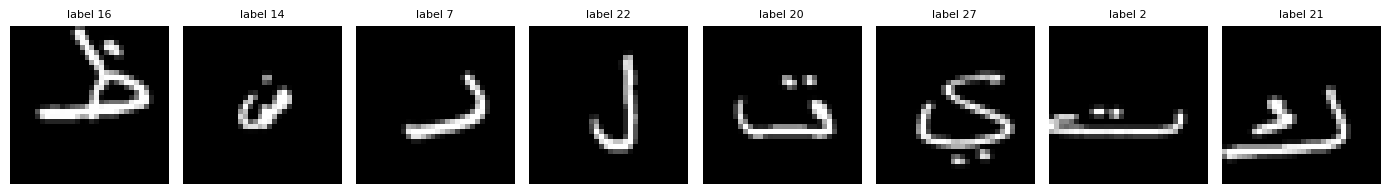

In [ ]:
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i in range(8):
    axes[i].imshow(X_tr[i, :, :, 0], cmap="gray")
    axes[i].set_title(f"label {y_tr[i]}", fontsize=8)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs("processed", exist_ok=True)
np.savez_compressed(
    "processed/ahcd_processed.npz",
    X_train=X_tr, y_train=y_tr,
    X_val=X_val, y_val=y_val,
    X_test=X_te, y_test=y_te,
)
print("Saved:", os.listdir("processed"))

Saved: ['ahcd_processed.npz']


In [ ]:
!git clone -q https://github.com/israksu/Hijja2.git
hijja_root = "Hijja2"

for root, dirs, files in os.walk(hijja_root):
    if ".git" in root:
        continue
    print(root, "| dirs:", len(dirs), "| files:", len(files))
    for f in files[:5]:
        print("    ", f)

Hijja2 | dirs: 30 | files: 4
     letterStats.xlsx
     README.md
     ~$letterStats.xlsx
     CSV.zip
Hijja2/24 mim | dirs: 4 | files: 1
     .DS_Store
Hijja2/24 mim/24.3 | dirs: 0 | files: 425
     26113.png
     26977.png
     18229.png
     27733.png
     949.png
Hijja2/24 mim/24.2 | dirs: 0 | files: 432
     29892.png
     39677.png
     44646.png
     4836.png
     40901.png
Hijja2/24 mim/24.4 | dirs: 0 | files: 434
     3110.png
     46472.png
     5594.png
     29138.png
     36199.png
Hijja2/24 mim/24.1 | dirs: 0 | files: 435
     46067.png
     43113.png
     10991.png
     46468.png
     25356.png
Hijja2/7 kha | dirs: 4 | files: 0
Hijja2/7 kha/7.3 | dirs: 0 | files: 454
     5749.png
     25621.png
     31021.png
     33830.png
     33505.png
Hijja2/7 kha/7.1 | dirs: 0 | files: 471
     41752.png
     15899.png
     15035.png
     43939.png
     37232.png
Hijja2/7 kha/7.2 | dirs: 0 | files: 466
     36130.png
     6396.png
     6504.png
     1536.png
     47872.png
Hijja2/7 

In [ ]:
import re
from PIL import Image

rows = []
for letter_dir in sorted(os.listdir(hijja_root)):
    letter_path = os.path.join(hijja_root, letter_dir)
    if not os.path.isdir(letter_path) or letter_dir.startswith("."):
        continue
    for sub in sorted(os.listdir(letter_path)):
        sub_path = os.path.join(letter_path, sub)
        if os.path.isdir(sub_path):
            n = len([f for f in os.listdir(sub_path) if f.endswith(".png")])
            rows.append((letter_dir, sub, n))

summary = pd.DataFrame(rows, columns=["letter_folder", "subfolder", "n_images"])
print(summary.to_string())
print("Total images:", summary["n_images"].sum())

sample = os.path.join(hijja_root, rows[0][0], rows[0][1])
img = Image.open(os.path.join(sample, os.listdir(sample)[0]))
print("Sample image size:", img.size, "| mode:", img.mode)

    letter_folder subfolder  n_images
0          1 alif       1.1       456
1          1 alif       1.2       443
2          1 alif       1.3       460
3          1 alif       1.4       460
4          1 alif       1.5       464
5          1 alif       1.6       458
6           10 ra      10.1       424
7           10 ra      10.2       423
8          11 zay      11.1       426
9          11 zay      11.2       434
10         12 sin      12.1       440
11         12 sin      12.2       427
12         12 sin      12.3       425
13         12 sin      12.4       437
14        13 shin      13.1       439
15        13 shin      13.2       412
16        13 shin      13.3       436
17        13 shin      13.4       420
18         14 sad      14.1       438
19         14 sad      14.2       427
20         14 sad      14.3       437
21         14 sad      14.4       421
22         15 dad      15.1       432
23         15 dad      15.2       402
24         15 dad      15.3       433
25         1

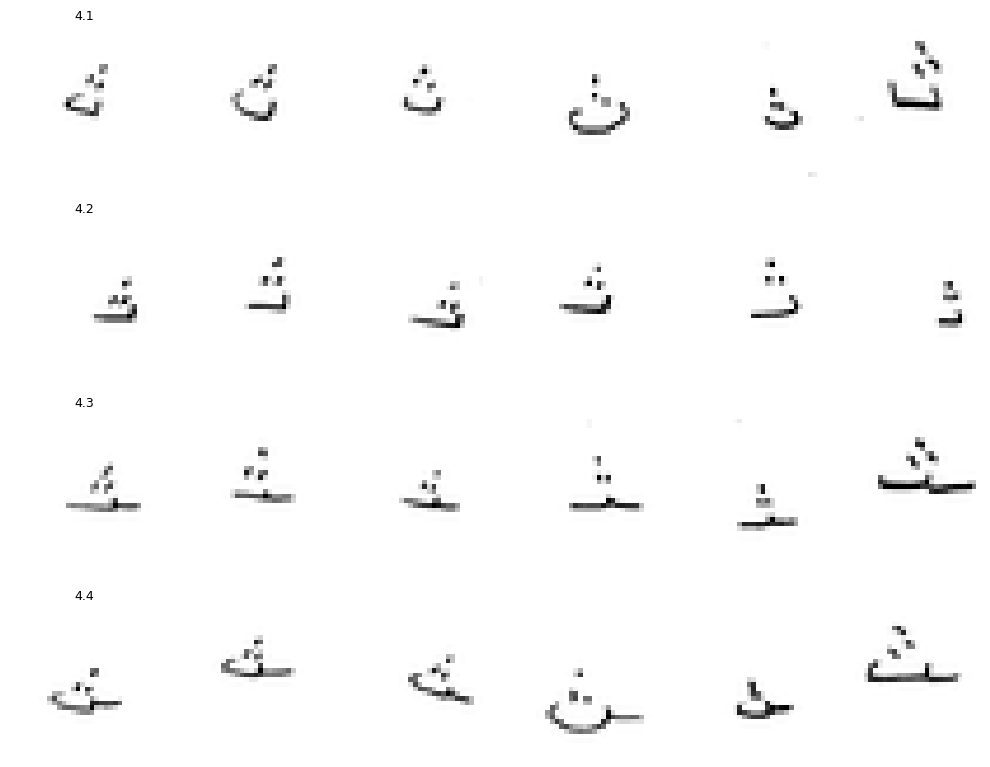

In [ ]:
letter_folder = "4 tha"
subs = sorted(d for d in os.listdir(os.path.join(hijja_root, letter_folder))
              if os.path.isdir(os.path.join(hijja_root, letter_folder, d)))

fig, axes = plt.subplots(len(subs), 6, figsize=(10, 2 * len(subs)))
for r, sub in enumerate(subs):
    folder = os.path.join(hijja_root, letter_folder, sub)
    files = sorted(os.listdir(folder))[:6]
    for c, fname in enumerate(files):
        axes[r, c].imshow(Image.open(os.path.join(folder, fname)).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(sub, fontsize=9)
plt.tight_layout()
plt.show()

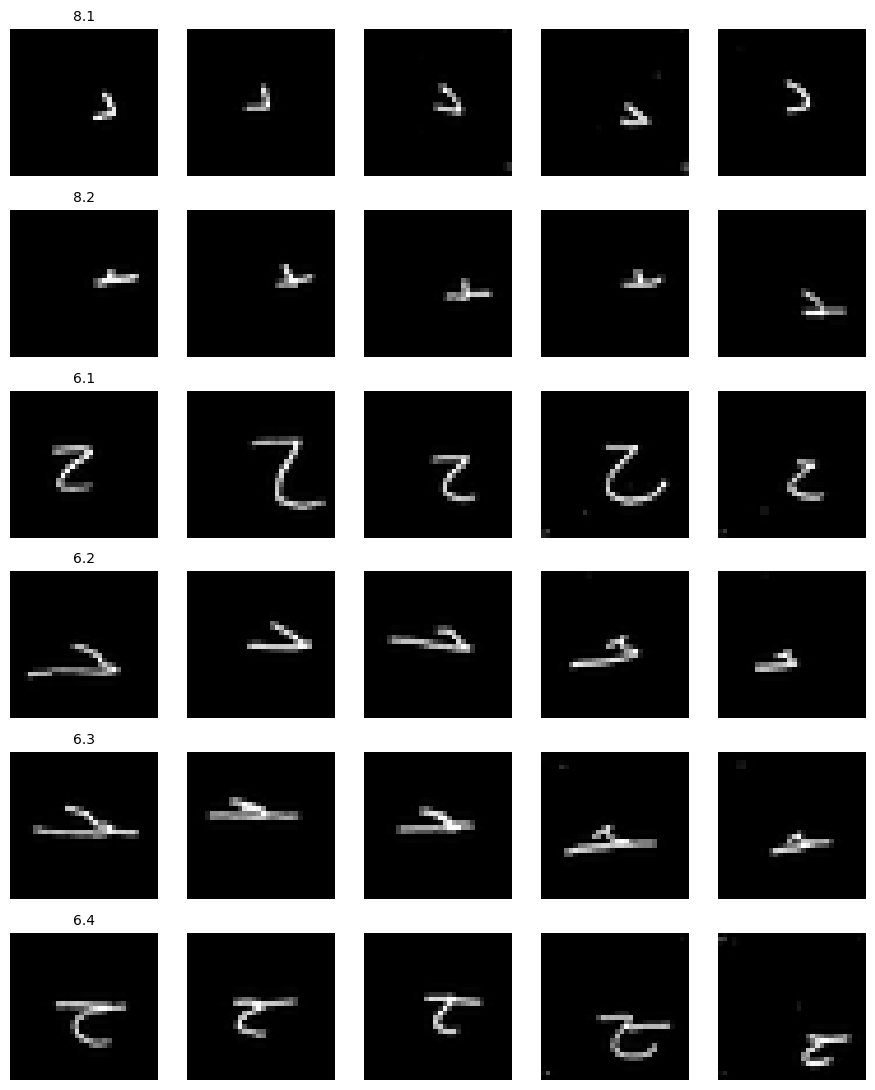

In [ ]:
from PIL import ImageOps

fig, axes = plt.subplots(6, 5, figsize=(9, 11))
row = 0
for letter_folder in ["8 dal", "6 ha"]:
    subs = sorted(d for d in os.listdir(os.path.join(hijja_root, letter_folder))
                  if os.path.isdir(os.path.join(hijja_root, letter_folder, d)))
    for sub in subs:
        folder = os.path.join(hijja_root, letter_folder, sub)
        files = sorted(os.listdir(folder))[:5]
        for c, fname in enumerate(files):
            img = ImageOps.invert(Image.open(os.path.join(folder, fname)).convert("L"))
            axes[row, c].imshow(img, cmap="gray")
            axes[row, c].axis("off")
            if c == 0:
                axes[row, c].set_title(sub, fontsize=10)
        row += 1
plt.tight_layout()
plt.show()

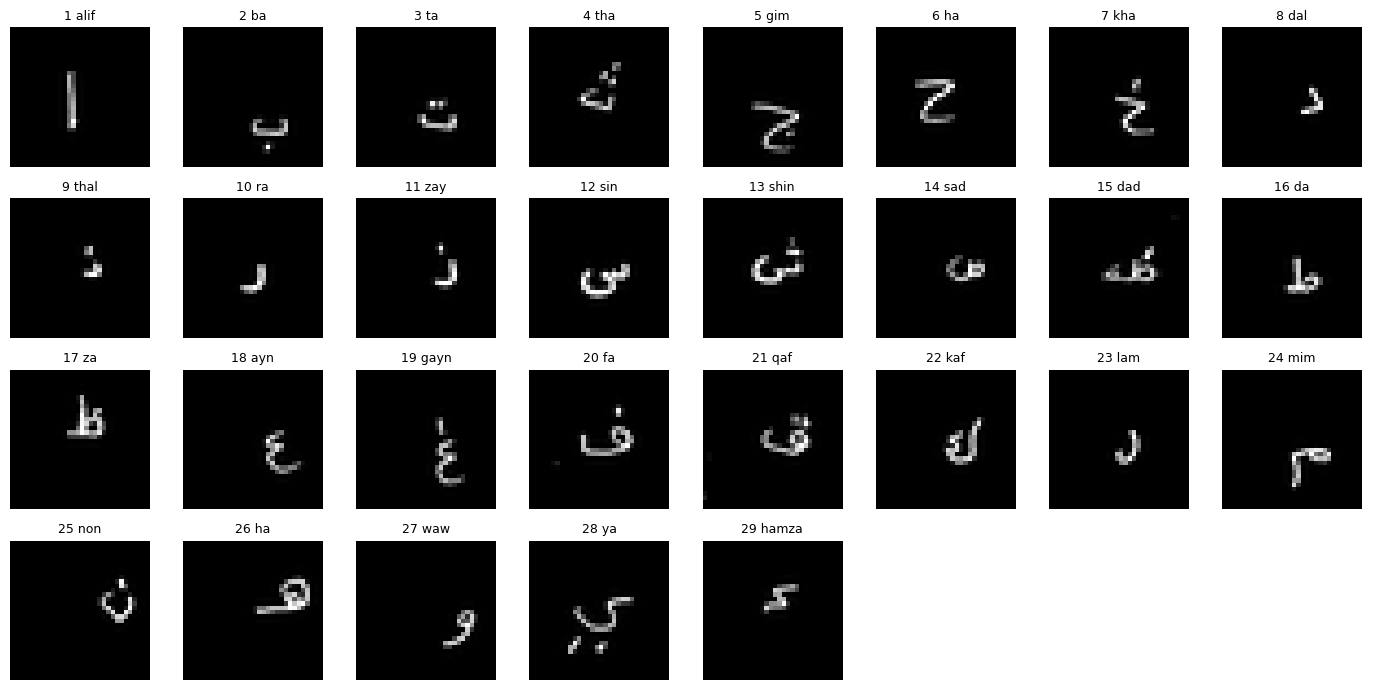

Letters found: 29


In [ ]:
letters = sorted(
    [d for d in os.listdir(hijja_root) if re.match(r"^\d+ ", d)],
    key=lambda d: int(d.split()[0]),
)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for ax in axes.ravel():
    ax.axis("off")

for ax, letter in zip(axes.ravel(), letters):
    num = letter.split()[0]
    folder = os.path.join(hijja_root, letter, num + ".1")
    fname = sorted(os.listdir(folder))[0]
    img = ImageOps.invert(Image.open(os.path.join(folder, fname)).convert("L"))
    ax.imshow(img, cmap="gray")
    ax.set_title(letter, fontsize=9)

plt.tight_layout()
plt.show()
print("Letters found:", len(letters))

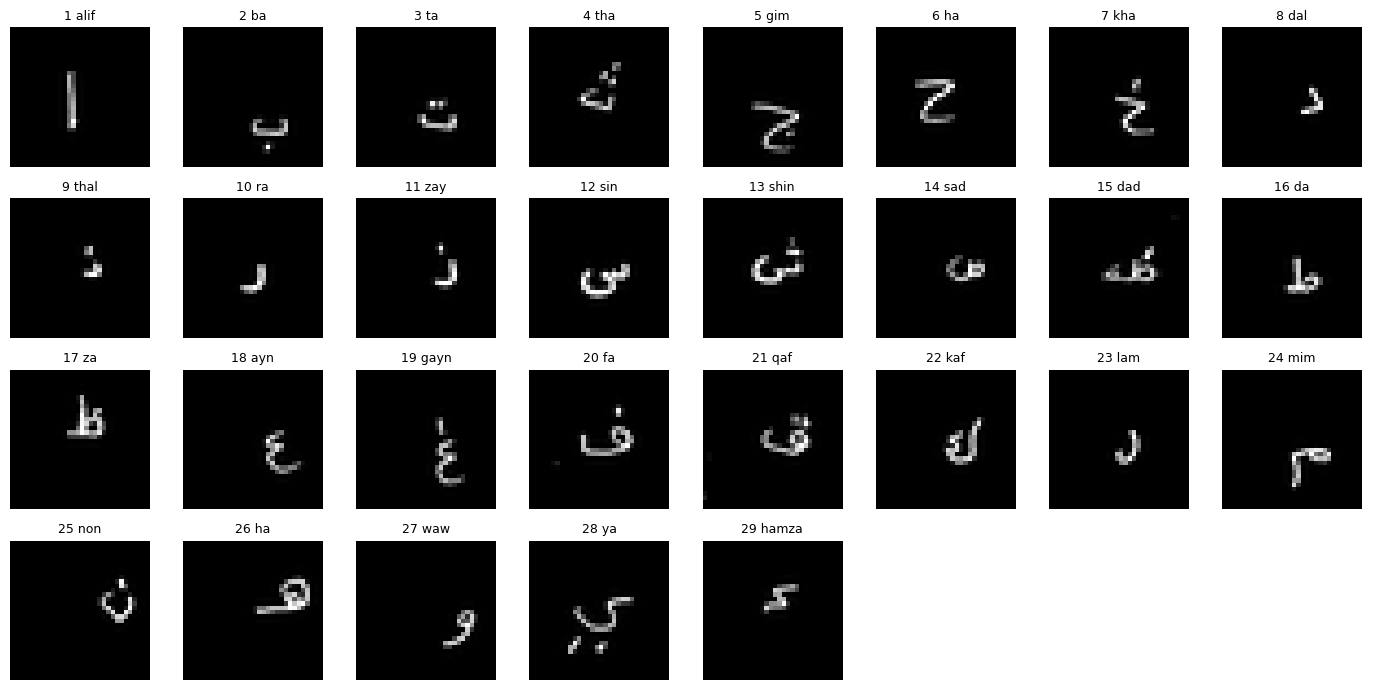

Letters found: 29


In [ ]:
letters = sorted(
    [d for d in os.listdir(hijja_root) if re.match(r"^\d+ ", d)],
    key=lambda d: int(d.split()[0]),
)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for ax in axes.ravel():
    ax.axis("off")

for ax, letter in zip(axes.ravel(), letters):
    num = letter.split()[0]
    folder = os.path.join(hijja_root, letter, num + ".1")
    fname = sorted(os.listdir(folder))[0]
    img = ImageOps.invert(Image.open(os.path.join(folder, fname)).convert("L"))
    ax.imshow(img, cmap="gray")
    ax.set_title(letter, fontsize=9)

plt.tight_layout()
plt.show()
print("Letters found:", len(letters))

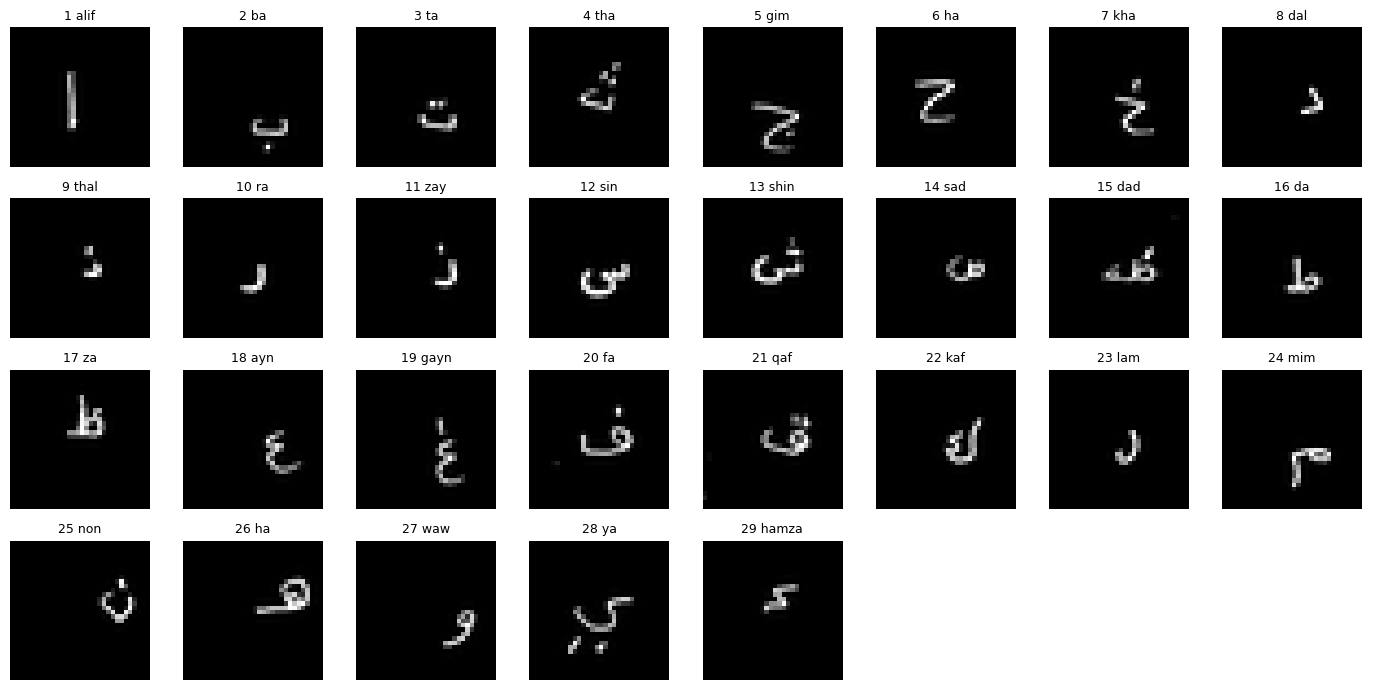

Letters found: 29


In [ ]:

letters = sorted(
    [d for d in os.listdir(hijja_root) if re.match(r"^\d+ ", d)],
    key=lambda d: int(d.split()[0]),
)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))

for ax in axes.ravel():
    ax.axis("off")

for ax, letter in zip(axes.ravel(), letters):
    num = letter.split()[0]
    folder = os.path.join(hijja_root, letter, num + ".1")
    fname = sorted(os.listdir(folder))[0]

    img = ImageOps.invert(
        Image.open(os.path.join(folder, fname)).convert("L")
    )

    ax.imshow(img, cmap="gray")
    ax.set_title(letter, fontsize=9)

plt.tight_layout()
plt.show()

print("Letters found:", len(letters))


In [ ]:
def load_hijja_isolated(root):
    X, y = [], []
    for letter in letters:
        num = int(letter.split()[0])
        if num == 29:
            continue
        folder = os.path.join(root, letter, str(num) + ".1")
        for fname in sorted(os.listdir(folder)):
            if not fname.endswith(".png"):
                continue
            img = Image.open(os.path.join(folder, fname)).convert("L")
            X.append(255 - np.asarray(img, dtype="uint8"))
            y.append(num - 1)
    X = np.stack(X).astype("float32") / 255.0
    return X[..., np.newaxis], np.array(y, dtype="int64")

X_h, y_h = load_hijja_isolated(hijja_root)

print("Hijja isolated:", X_h.shape, "| labels:", y_h.min(), "to", y_h.max())
print("Classes:", len(np.unique(y_h)))
print("Pixel range:", X_h.min(), "to", X_h.max())
print("Mean pixel  Hijja:", round(float(X_h.mean()), 3), "| AHCD:", round(float(X_te.mean()), 3))

counts = pd.Series(y_h).value_counts().sort_index()
print("Images per class: min", counts.min(), "| max", counts.max())

os.makedirs("processed", exist_ok=True)
np.savez_compressed("processed/hijja_isolated.npz", X=X_h, y=y_h)
print("Saved:", os.listdir("processed"))

Hijja isolated: (12351, 32, 32, 1) | labels: 0 to 27
Classes: 28
Pixel range: 0.0 to 1.0
Mean pixel  Hijja: 0.025 | AHCD: 0.053
Images per class: min 422 | max 472
Saved: ['hijja_isolated.npz', 'ahcd_processed.npz']


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(SEED)
NUM_CLASSES = 28

def build_baseline():
    return models.Sequential([
        layers.Input(shape=(32, 32, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="baseline_cnn")

def build_proposed():
    return models.Sequential([
        layers.Input(shape=(32, 32, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="proposed_cnn")

baseline = build_baseline()
proposed = build_proposed()
baseline.summary()
proposed.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 28)             │       114,716 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133,532 (521.61 KB)

 Trainable params: 133,532 (521.61 KB)

 Non-trainable params: 0 (0.00 B)

Model: "proposed_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,668 (377.61 KB)

 Trainable params: 96,476 (376.86 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

EPOCHS = 30
BATCH = 64
LR = 1e-3

def train_model(build_fn, name):
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LR),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH,
        callbacks=[stop], verbose=0,
    )
    test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
    print(name, "| epochs run:", len(hist.history["loss"]),
          "| best val acc:", round(max(hist.history["val_accuracy"]), 4),
          "| TEST acc:", round(test_acc, 4))
    model.save("processed/" + name + ".keras")
    return model, hist

baseline, hist_b = train_model(build_baseline, "baseline_cnn")
proposed, hist_p = train_model(build_proposed, "proposed_cnn")

baseline_cnn | epochs run: 11 | best val acc: 0.8705 | TEST acc: 0.8765
proposed_cnn | epochs run: 15 | best val acc: 0.9501 | TEST acc: 0.9592


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(
    X_h, y_h, test_size=0.2, stratify=y_h, random_state=SEED
)
np.savez_compressed("processed/hijja_split.npz",
                    X_train=Xh_tr, y_train=yh_tr, X_test=Xh_te, y_test=yh_te)

def evaluate(model, X, y):
    pred = model.predict(X, verbose=0).argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(
        y, pred, average="macro", zero_division=0
    )
    return accuracy_score(y, pred), p, r, f1

rows = []
for name, m in [("baseline", baseline), ("proposed", proposed)]:
    for ds, (X, y) in [("AHCD test", (X_te, y_te)),
                       ("Hijja test (no fine-tuning)", (Xh_te, yh_te))]:
        acc, p, r, f1 = evaluate(m, X, y)
        rows.append([name, ds, round(acc, 4), round(p, 4), round(r, 4), round(f1, 4)])

results = pd.DataFrame(
    rows, columns=["model", "test set", "accuracy", "macro precision", "macro recall", "macro F1"]
)
print("Hijja train:", Xh_tr.shape, "| Hijja test:", Xh_te.shape)
print(results.to_string(index=False))
results.to_csv("processed/results_zero_shot.csv", index=False)

Hijja train: (9880, 32, 32, 1) | Hijja test: (2471, 32, 32, 1)
   model                    test set  accuracy  macro precision  macro recall  macro F1
baseline                   AHCD test    0.8765           0.8794        0.8765    0.8767
baseline Hijja test (no fine-tuning)    0.3958           0.5298        0.3953    0.3938
proposed                   AHCD test    0.9592           0.9601        0.9592    0.9592
proposed Hijja test (no fine-tuning)    0.5071           0.6980        0.5066    0.5321


In [ ]:
!zip -r -q outputs.zip processed
from google.colab import files
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>